<a href="https://colab.research.google.com/github/yeyevtushenko/Methods-and-Technologies-of-Computational-Intelligence/blob/main/%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%D0%B8_%D1%82%D0%B0_%D1%82%D0%B5%D1%85%D0%BD%D0%BE%D0%BB%D0%BE%D0%B3%D1%96%D1%97_%D0%BE%D0%B1%D1%87%D0%B8%D1%81%D0%BB%D1%8E%D0%B2%D0%B0%D0%BB%D1%8C%D0%BD%D0%BE%D0%B3%D0%BE_%D1%96%D0%BD%D1%82%D0%B5%D0%BB%D0%B5%D0%BA%D1%82%D1%83_%D0%97%D0%9A_61%D0%9F%D0%9C_%D0%84%D0%B2%D1%82%D1%83%D1%88%D0%B5%D0%BD%D0%BA%D0%BE_%D0%BF%D1%80%D0%BE%D0%B4%D0%B2%D0%B8%D0%BD%D1%83%D1%82%D0%B8%D0%B9_%D0%9B%D0%B0%D0%B1%E2%84%965.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Імпорт бібліотек

In [1]:
%pip install -q ucimlrepo

import time
import itertools
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from sklearn.metrics import (
    balanced_accuracy_score, accuracy_score,
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    confusion_matrix, classification_report,
    RocCurveDisplay, PrecisionRecallDisplay
)

warnings.filterwarnings('ignore')

# Завдання 1. Дані, class imbalance та пропущені значення

> Завантажити датасет, проаналізувати class imbalance та missing values.

In [ ]:
dataset = fetch_ucirepo(id=383)

X = dataset.data.features.copy()

print("Targets (ucimlrepo):", dataset.data.targets)
print("X:", X.shape)
print(X.head())
print(X.dtypes.value_counts())

Targets (ucimlrepo): None
X: (858, 36)
   Age  Number of sexual partners  First sexual intercourse  \
0   18                        4.0                      15.0   
1   15                        1.0                      14.0   
2   34                        1.0                       NaN   
3   52                        5.0                      16.0   
4   46                        3.0                      21.0   

   Num of pregnancies  Smokes  Smokes (years)  Smokes (packs/year)  \
0                 1.0     0.0             0.0                  0.0   
1                 1.0     0.0             0.0                  0.0   
2                 1.0     0.0             0.0                  0.0   
3                 4.0     1.0            37.0                 37.0   
4                 4.0     0.0             0.0                  0.0   

   Hormonal Contraceptives  Hormonal Contraceptives (years)  IUD  ...  \
0                      0.0                              0.0  0.0  ...   
1              

Набір містить 858 пацієнток і 36 стовпців. У `ucimlrepo` для цього набору `targets` порожній (`None`): усі стовпці, зокрема цільовий `Biopsy` та діагностичні `Hinselmann`, `Schiller`, `Citology`, лежать у `features`. Тому код теорії з `dataset.data.targets` не працює, і ціль береться зі стовпця `Biopsy`. Значення `?` замінюються на NaN, усі стовпці приводяться до числових.

In [ ]:
X = X.replace("?", np.nan)

for col in X.columns:
    X[col] = pd.to_numeric(X[col], errors="coerce")

target = "Biopsy"
y = X[target].astype(int)

leakage_cols = ["Hinselmann", "Schiller", "Citology"]
X = X.drop(columns=[c for c in leakage_cols + [target] if c in X.columns], errors="ignore")

print("X без цілей:", X.shape)
print(y.value_counts())
print(y.value_counts(normalize=True))
print("Missing fraction:")
print(X.isna().mean().sort_values(ascending=False).head(15))
print("Стовпців із пропусками:", int((X.isna().sum() > 0).sum()), "з", X.shape[1])
print("Рядків із хоча б одним пропуском:", int(X.isna().any(axis=1).sum()), "з", len(X))
print("Константні ознаки:", X.columns[X.nunique() <= 1].tolist())

X без цілей: (858, 32)
Biopsy
0    803
1     55
Name: count, dtype: int64
Biopsy
0    0.935897
1    0.064103
Name: proportion, dtype: float64
Missing fraction:
STDs: Time since last diagnosis     0.917249
STDs: Time since first diagnosis    0.917249
IUD                                 0.136364
IUD (years)                         0.136364
Hormonal Contraceptives             0.125874
Hormonal Contraceptives (years)     0.125874
STDs:vaginal condylomatosis         0.122378
STDs:HPV                            0.122378
STDs:Hepatitis B                    0.122378
STDs:HIV                            0.122378
STDs:AIDS                           0.122378
STDs:molluscum contagiosum          0.122378
STDs:genital herpes                 0.122378
STDs:pelvic inflammatory disease    0.122378
STDs:syphilis                       0.122378
dtype: float64
Стовпців із пропусками: 26 з 32
Рядків із хоча б одним пропуском: 799 з 858
Константні ознаки: ['STDs:cervical condylomatosis', 'STDs:AIDS']


Клас дуже незбалансований: 803 пацієнтки з `Biopsy = 0` (93.6%) і лише 55 із `Biopsy = 1` (6.4%). Із 32 ознак (після видалення 4 діагностичних стовпців) пропуски має 26, а 799 із 858 рядків мають хоча б один пропуск. Найбільша частка пропусків (91.7%) у `STDs: Time since first diagnosis` та `STDs: Time since last diagnosis`, далі стовпці про внутрішньоматкову спіраль (13.6%), гормональну контрацепцію (12.6%) і окремі STDs (12.2%). Повністю порожніх стовпців немає, але дві ознаки (`STDs:cervical condylomatosis` і `STDs:AIDS`) константні. Стовпці `Hinselmann`, `Schiller` і `Citology` це результати інших діагностичних тестів, які дають очевидну підказку для біопсії, тому вони виключені з ознак разом із самою ціллю.

# Завдання 2. Preprocessing та протокол train/test

> Побудувати коректний preprocessing pipeline без leakage.

Imputer і scaler входять до `Pipeline` кожної моделі, тому навчаються лише на навчальній частині (а в кросс-валідації лише на її навчальних фолдах).

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    stratify=y,
    random_state=42
)

print("Train:", X_train.shape, ", positives:", int(y_train.sum()))
print("Test:", X_test.shape, ", positives:", int(y_test.sum()))
print("Train positive rate:", y_train.mean())
print("Test positive rate:", y_test.mean())
print("Accuracy константного прогнозу «усі здорові» на тесті:", 1 - y_test.mean())

Train: (643, 32) , positives: 41
Test: (215, 32) , positives: 14
Train positive rate: 0.06376360808709176
Test positive rate: 0.06511627906976744
Accuracy константного прогнозу «усі здорові» на тесті: 0.9348837209302325


Стратифіковане розбиття дає 643 пацієнтки в навчальній частині (41 позитивна, 6.38%) і 215 у тестовій (14 позитивних, 6.51%). Тестова вибірка містить лише 14 позитивних випадків, тому кожен виявлений чи пропущений випадок змінює sensitivity на 7 п.п., і всі оцінки на тесті дуже шумні. Константний прогноз «усі здорові» на тесті має accuracy 0.935, тобто accuracy не може бути основною метрикою.

# Завдання 3. Базові моделі та порівняння

> Навчити щонайменше чотири різнорідні базові моделі. Порівняти їх за BAcc, sensitivity, specificity, F1, ROC-AUC та PR-AUC.

In [ ]:
def evaluate_model(name, y_true, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    cm = confusion_matrix(y_true, pred)
    tn, fp, fn, tp = cm.ravel()

    specificity = tn / (tn + fp + 1e-12)

    return {
        "Model": name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_true, pred),
        "BAcc": balanced_accuracy_score(y_true, pred),
        "Sensitivity": recall_score(y_true, pred, zero_division=0),
        "Specificity": specificity,
        "Precision": precision_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, prob),
        "PR_AUC": average_precision_score(y_true, prob),
        "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn)
    }

def build_models(seed=42):
    logreg = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=3000,
            class_weight="balanced"
        ))
    ])

    rf = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=400,
            class_weight="balanced",
            random_state=seed
        ))
    ])

    extra = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", ExtraTreesClassifier(
            n_estimators=400,
            class_weight="balanced",
            random_state=seed
        ))
    ])

    boost = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", HistGradientBoostingClassifier(
            max_iter=200,
            learning_rate=0.05,
            random_state=seed
        ))
    ])

    return {
        "Logistic Regression": logreg,
        "Random Forest": rf,
        "Extra Trees": extra,
        "Boosting": boost
    }

models = build_models(42)
logreg, rf, extra, boost = (models[k] for k in ["Logistic Regression", "Random Forest", "Extra Trees", "Boosting"])

results = []
test_probabilities = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    prob = model.predict_proba(X_test)[:, 1]

    test_probabilities[name] = prob
    results.append(
        evaluate_model(name, y_test, prob, threshold=0.5)
    )

results_df = pd.DataFrame(results)
print(results_df.sort_values("PR_AUC", ascending=False).round(4).to_string(index=False))

              Model  Threshold  Accuracy   BAcc  Sensitivity  Specificity  Precision     F1  ROC_AUC  PR_AUC  TP  FP  FN  TN
        Extra Trees        0.5    0.9349 0.5665       0.1429       0.9900     0.5000 0.2222   0.7754  0.2275   2   2  12 199
           Boosting        0.5    0.9256 0.5283       0.0714       0.9851     0.2500 0.1111   0.6994  0.2006   1   3  13 198
      Random Forest        0.5    0.9163 0.5565       0.1429       0.9701     0.2500 0.1818   0.7097  0.1957   2   6  12 195
Logistic Regression        0.5    0.8000 0.6604       0.5000       0.8209     0.1628 0.2456   0.6354  0.1909   7  36   7 165


При порозі 0.5 `Logistic Regression` (з `class_weight="balanced"`) має найвищу BAcc (0.660) і sensitivity 0.500, але 36 хибнопозитивних (specificity 0.821). Три ансамблі дерев майже не знаходять позитивних випадків: Extra Trees виявив 2 з 14 (sensitivity 0.143), Random Forest 2, Boosting 1 (0.071), при цьому accuracy 0.916 – 0.935, що близько до константного прогнозу 0.935. За PR-AUC порядок: Extra Trees (0.228), Boosting (0.201), Random Forest (0.196), Logistic Regression (0.191), тобто всі в діапазоні 0.19 – 0.23 при частці позитивних 0.065 (приблизно втричі вище за випадковий рівень). За ROC-AUC: Extra Trees 0.775, Random Forest 0.710, Boosting 0.699, Logistic Regression 0.635. Отже, регресія виглядає найкращою за BAcc при порозі 0.5, але останньою за ROC-AUC і PR-AUC: тут працює вибір точки на кривій, а не краще впорядкування.

# Завдання 4. ROC та Precision–Recall curves

> Побудувати ROC і Precision–Recall curves.

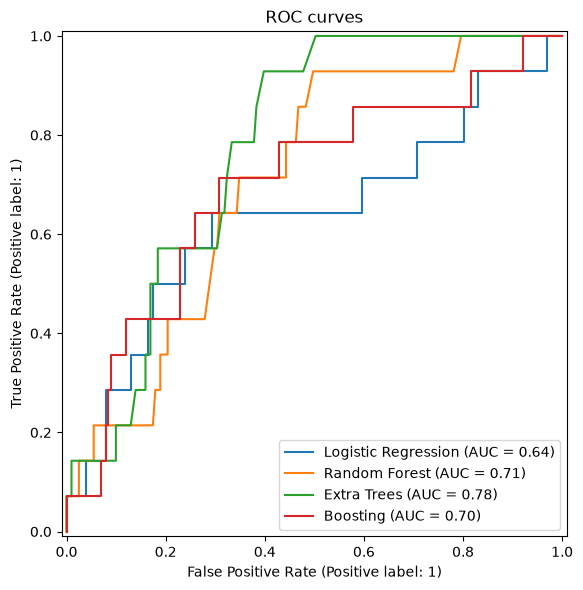

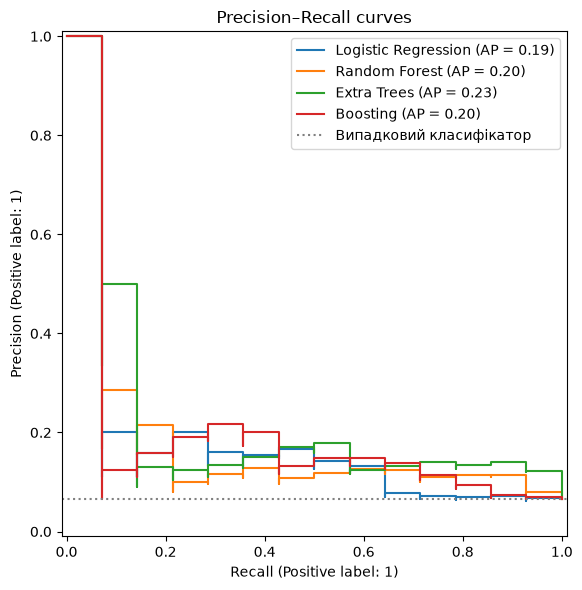

Ранги за ROC-AUC: ['Extra Trees', 'Random Forest', 'Boosting', 'Logistic Regression']
Ранги за PR-AUC: ['Extra Trees', 'Boosting', 'Random Forest', 'Logistic Regression']


In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, prob in test_probabilities.items():
    RocCurveDisplay.from_predictions(
        y_test, prob, name=name, ax=ax
    )
plt.title("ROC curves")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 6))
for name, prob in test_probabilities.items():
    PrecisionRecallDisplay.from_predictions(
        y_test, prob, name=name, ax=ax
    )
ax.axhline(y_test.mean(), color="gray", linestyle=":", label="Випадковий класифікатор")
ax.legend()
plt.title("Precision–Recall curves")
plt.tight_layout()
plt.show()

print("Ранги за ROC-AUC:", results_df.sort_values("ROC_AUC", ascending=False)["Model"].tolist())
print("Ранги за PR-AUC:", results_df.sort_values("PR_AUC", ascending=False)["Model"].tolist())

Висновок про найкращу модель не однаковий для різних метрик: за ROC-AUC і PR-AUC перше місце займає Extra Trees (0.775 і 0.228), а Logistic Regression в обох випадках остання (0.635 і 0.191), хоча Random Forest і Boosting міняються місцями (ROC: Random Forest 0.710 проти 0.699, PR: Boosting 0.201 проти 0.196). Усі PR-AUC лежать у вузькому діапазоні близько 0.2 при випадковому рівні 0.065, тобто якість прогнозування помірна для всіх моделей, а різниці між моделями невеликі й за 14 позитивних випадків не надійні.

# Завдання 5. Soft Voting

> Побудувати Soft Voting ensemble.

In [ ]:
voting = VotingClassifier(
    estimators=[
        ("lr", logreg),
        ("rf", rf),
        ("extra", extra),
        ("boost", boost)
    ],
    voting="soft"
)

voting.fit(X_train, y_train)
voting_prob = voting.predict_proba(X_test)[:, 1]

print(pd.DataFrame([
    evaluate_model("Soft Voting", y_test, voting_prob)
]).round(4).to_string(index=False))

mean_prob = np.mean([test_probabilities[k] for k in test_probabilities], axis=0)
print("Максимальна різниця між VotingClassifier та середнім ймовірностей базових моделей:", np.abs(voting_prob - mean_prob).max())

      Model  Threshold  Accuracy  BAcc  Sensitivity  Specificity  Precision     F1  ROC_AUC  PR_AUC  TP  FP  FN  TN
Soft Voting        0.5    0.9302 0.564       0.1429       0.9851        0.4 0.2105   0.7399  0.2301   2   3  12 198
Максимальна різниця між VotingClassifier та середнім ймовірностей базових моделей: 0.0


Soft Voting (усереднення чотирьох моделей) при порозі 0.5 має BAcc 0.564, sensitivity 0.143 (2 із 14), specificity 0.985, ROC-AUC 0.740 і PR-AUC 0.230. Це майже збігається з Extra Trees (PR-AUC 0.228) і не перевершує його. Перевірка показала, що результат `VotingClassifier` збігається з простим середнім ймовірностей базових моделей (максимальна різниця 0.0). Домінують дерева: оскільки три з чотирьох моделей це дерева, які дають малі ймовірності для позитивного класу, усереднена ймовірність рідко перевищує 0.5, і sensitivity лишається низькою.

# Завдання 6. Stacking

> Побудувати Stacking ensemble.

In [ ]:
stacking = StackingClassifier(
    estimators=[
        ("lr", logreg),
        ("rf", rf),
        ("extra", extra),
        ("boost", boost)
    ],
    final_estimator=LogisticRegression(
        max_iter=3000,
        class_weight="balanced"
    ),
    stack_method="predict_proba",
    cv=5
)

stacking.fit(X_train, y_train)
stack_prob = stacking.predict_proba(X_test)[:, 1]

print(pd.DataFrame([
    evaluate_model("Stacking", y_test, stack_prob)
]).round(4).to_string(index=False))
print("Коефіцієнти мета-моделі (lr, rf, extra, boost):", stacking.final_estimator_.coef_.round(3))

   Model  Threshold  Accuracy   BAcc  Sensitivity  Specificity  Precision     F1  ROC_AUC  PR_AUC  TP  FP  FN  TN
Stacking        0.5    0.7674 0.7095       0.6429       0.7761     0.1667 0.2647   0.7633  0.2295   9  45   5 156
Коефіцієнти мета-моделі (lr, rf, extra, boost): [[0.461 0.139 1.65  0.93 ]]


Stacking при порозі 0.5 має BAcc 0.710, sensitivity 0.643 (9 із 14), specificity 0.776, ROC-AUC 0.763 і PR-AUC 0.229. Тобто за BAcc він значно кращий за Voting (0.564), але за ROC-AUC і PR-AUC практично такий самий (0.763 проти 0.740 і 0.229 проти 0.230). Різниця в BAcc пояснюється мета-моделлю з `class_weight="balanced"`, яка зміщує вихідні ймовірності вгору, і тому при порозі 0.5 позитивних випадків виявляється більше (45 хибнопозитивних проти 3). Коефіцієнти мета-моделі (lr 0.461, rf 0.139, extra 1.650, boost 0.930) показують, що найбільше вона покладається на Extra Trees, а Random Forest майже ігнорує.

# Завдання 7. Threshold tuning

> Виконати threshold tuning лише на training data через out-of-fold predictions.

Час, с: 21.1
Selected threshold: 0.4900000000000001
OOF BAcc: 0.6032331253545093
OOF BAcc при порозі 0.5: 0.5929624827809741


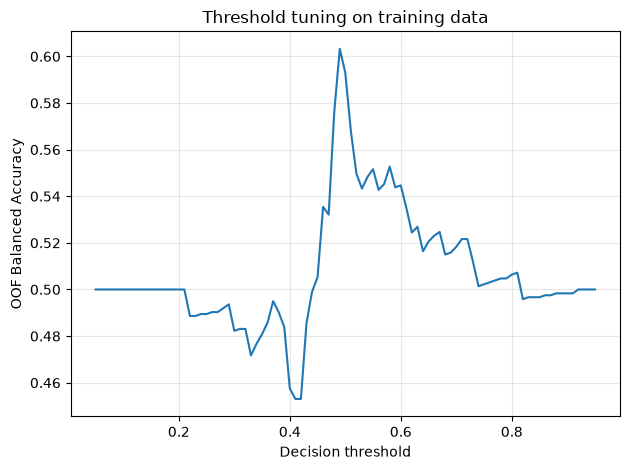

In [ ]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

t0 = time.time()
oof_prob = cross_val_predict(
    stacking,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]
print("Час, с:", round(time.time() - t0, 1))

thresholds = np.arange(0.05, 0.96, 0.01)
bacc_scores = []

for t in thresholds:
    pred = (oof_prob >= t).astype(int)
    bacc_scores.append(
        balanced_accuracy_score(y_train, pred)
    )

best_threshold = thresholds[np.argmax(bacc_scores)]

print("Selected threshold:", best_threshold)
print("OOF BAcc:", max(bacc_scores))
print("OOF BAcc при порозі 0.5:", bacc_scores[int(np.argmin(np.abs(thresholds - 0.5)))])

plt.plot(thresholds, bacc_scores)
plt.xlabel("Decision threshold")
plt.ylabel("OOF Balanced Accuracy")
plt.title("Threshold tuning on training data")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Поріг, підібраний за out-of-fold прогнозами навчальної частини з критерієм максимуму BAcc, дорівнює 0.49, тобто майже не відрізняється від 0.5. OOF BAcc при цьому 0.603 проти 0.593 при порозі 0.5, тобто кросвалідаційна оцінка якості стекінга значно нижча за тестову (0.71 – 0.73), що вказує на шумність обох оцінок і малу кількість позитивних випадків (41 на навчальній частині).

In [ ]:
default_result = evaluate_model(
    "Stacking, threshold=0.5",
    y_test,
    stack_prob,
    threshold=0.5
)

tuned_result = evaluate_model(
    "Stacking, tuned threshold",
    y_test,
    stack_prob,
    threshold=best_threshold
)

print(pd.DataFrame([
    default_result,
    tuned_result
]).T)

final_pred = (stack_prob >= best_threshold).astype(int)
print(confusion_matrix(y_test, final_pred))
print(classification_report(y_test, final_pred, digits=4))

                                   0                          1
Model        Stacking, threshold=0.5  Stacking, tuned threshold
Threshold                        0.5                       0.49
Accuracy                    0.767442                   0.748837
BAcc                        0.709488                   0.732765
Sensitivity                 0.642857                   0.714286
Specificity                 0.776119                   0.751244
Precision                   0.166667                   0.166667
F1                          0.264706                    0.27027
ROC_AUC                     0.763326                   0.763326
PR_AUC                      0.229451                   0.229451
TP                                 9                         10
FP                                45                         50
FN                                 5                          4
TN                               156                        151
[[151  50]
 [  4  10]]
              pre

Підібраний поріг (0.49) змінює результат незначно: sensitivity зростає з 0.643 до 0.714 (10 із 14 замість 9), BAcc з 0.7095 до 0.7328, а специфічність знижується з 0.776 до 0.751 (50 хибнопозитивних замість 45). Різниця це один додатково виявлений позитивний випадок і п'ять додаткових хибних тривог, тобто це в межах шуму. Матриця помилок фінальної моделі: TN 151, FP 50, FN 4, TP 10; precision позитивного класу 0.167, тобто лише кожен шостий пацієнт, позначений як ризиковий, справді має позитивну біопсію, а recall 0.714.

# Завдання 8. Експерименти

> Провести всі експерименти з розділу 18.

> 1. Class weighting: LogReg/RF з class_weight=None та balanced. Що аналізувати: Sensitivity, specificity, PR-AUC.
> 2. Bagging vs Boosting: Random Forest / Extra Trees / Boosting. Що аналізувати: типи помилок та стабільність.
> 3. Voting composition: 2, 3 і 4 базові моделі. Що аналізувати: чи завжди більше моделей краще.
> 4. Stacking meta-model: Logistic Regression; Random Forest. Що аналізувати: якість та ризик overfitting.
> 5. Threshold criterion: max BAcc; max F1; sensitivity ≥ 0.80. Що аналізувати: клінічний trade-off.
> 6. Random seeds: щонайменше 5 seeds для tree ensembles. Що аналізувати: середнє ± std основних метрик.

In [ ]:
SEEDS = [0, 1, 2, 3, 4]
METRIC_COLS = ["BAcc", "Sensitivity", "Specificity", "F1", "ROC_AUC", "PR_AUC"]

def mean_std(rows, cols=METRIC_COLS):
    table = pd.DataFrame(rows)
    return {c: f"{table[c].mean():.3f} ± {table[c].std(ddof=0):.3f}" for c in cols}

Усі експерименти (крім останнього) використовують той самий split і поріг 0.5. Оскільки в тесті всього 14 позитивних випадків, окремі різниці в кількох об'єктах не є надійними, тому для стохастичних моделей наведено середнє ± std за 5 seeds, а в експерименті 6 додатково використано 5 різних розбиттів train/test.

# Експеримент 1. Class weighting

In [ ]:
def make_logreg(cw):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=3000, class_weight=cw))
    ])

def make_rf(cw, seed):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(n_estimators=400, class_weight=cw, random_state=seed))
    ])

rows = {}
for cw in [None, "balanced"]:
    p = make_logreg(cw).fit(X_train, y_train).predict_proba(X_test)[:, 1]
    r = evaluate_model("", y_test, p)
    rows[f"LogReg, class_weight={cw}"] = {**{c: f"{r[c]:.3f}" for c in METRIC_COLS}, "FP": r["FP"], "FN": r["FN"]}

    rr = [evaluate_model("", y_test, make_rf(cw, s).fit(X_train, y_train).predict_proba(X_test)[:, 1]) for s in SEEDS]
    rows[f"Random Forest, class_weight={cw}"] = {**mean_std(rr), "FP": np.mean([r["FP"] for r in rr]), "FN": np.mean([r["FN"] for r in rr])}

print(pd.DataFrame(rows).T.to_string())

                                               BAcc    Sensitivity    Specificity             F1        ROC_AUC         PR_AUC   FP    FN
LogReg, class_weight=None                     0.533          0.071          0.995          0.125          0.679          0.208    1    13
Random Forest, class_weight=None      0.536 ± 0.000  0.071 ± 0.000  1.000 ± 0.000  0.133 ± 0.000  0.713 ± 0.015  0.215 ± 0.003  0.0  13.0
LogReg, class_weight=balanced                 0.660          0.500          0.821          0.246          0.635          0.191   36     7
Random Forest, class_weight=balanced  0.550 ± 0.015  0.129 ± 0.029  0.971 ± 0.002  0.166 ± 0.036  0.715 ± 0.007  0.199 ± 0.003  5.8  12.2


Для Logistic Regression ваги класів змінюють робочу точку: з `class_weight=None` sensitivity 0.071 і specificity 0.995, зі `balanced` sensitivity 0.500 і specificity 0.821 (FN з 13 до 7, FP з 1 до 36). Для Random Forest ефект слабший: sensitivity 0.071 ± 0.000 без ваг і 0.129 ± 0.029 зі зваженням, а specificity знижується з 1.000 до 0.971. Показники, що не залежать від порогу, не покращуються: PR-AUC для Logistic Regression 0.208 без ваг і 0.191 зі зваженням, для Random Forest 0.215 і 0.199, ROC-AUC для Logistic Regression 0.679 і 0.635. Тобто class weighting переміщує модель по тій самій кривій, помітно підвищуючи sensitivity ціною specificity, але не покращує впорядкування пацієнтів.

# Експеримент 2. Bagging та Boosting

In [ ]:
rows = {}
probs_by_model = {}
for name in ["Random Forest", "Extra Trees", "Boosting"]:
    rr = []
    for s in SEEDS:
        m = build_models(s)[name].fit(X_train, y_train)
        p = m.predict_proba(X_test)[:, 1]
        rr.append(evaluate_model(name, y_test, p))
    rows[name] = {**mean_std(rr), "FP": f"{np.mean([r['FP'] for r in rr]):.1f}", "FN": f"{np.mean([r['FN'] for r in rr]):.1f}",
                  "FN (мін-макс)": f"{min(r['FN'] for r in rr)}-{max(r['FN'] for r in rr)}"}

print(pd.DataFrame(rows).T.to_string())

                        BAcc    Sensitivity    Specificity             F1        ROC_AUC         PR_AUC   FP    FN FN (мін-макс)
Random Forest  0.550 ± 0.015  0.129 ± 0.029  0.971 ± 0.002  0.166 ± 0.036  0.715 ± 0.007  0.199 ± 0.003  5.8  12.2         12-13
Extra Trees    0.566 ± 0.000  0.143 ± 0.000  0.990 ± 0.000  0.222 ± 0.000  0.762 ± 0.010  0.223 ± 0.002  2.0  12.0         12-12
Boosting       0.528 ± 0.000  0.071 ± 0.000  0.985 ± 0.000  0.111 ± 0.000  0.699 ± 0.000  0.201 ± 0.000  3.0  13.0         13-13


Bagging-моделі (Random Forest, Extra Trees) і Boosting діляться за типом помилок так: усі три мають високу specificity (0.971, 0.990, 0.985) і низьку sensitivity (0.129 ± 0.029, 0.143, 0.071), тобто пропускають 12 – 13 із 14 позитивних. Extra Trees має найменше хибнопозитивних (2) і найвищі ROC-AUC (0.762 ± 0.010) і PR-AUC (0.223 ± 0.002), Random Forest має 5.8 FP, Boosting 3 (ROC-AUC 0.699). Стабільність між seeds висока: std ROC-AUC 0.007 для Random Forest і 0.010 для Extra Trees, std PR-AUC близько 0.003; у Boosting з цими параметрами результат ідентичний для всіх seeds (std 0.000, випадковості немає). Тобто на цих даних різниця між bagging та boosting невелика і не перевищує різниці між розбиттями (див. експеримент 6), а Extra Trees виглядає трохи кращим на цьому розбитті.

# Експеримент 3. Склад Voting

In [ ]:
def soft_vote(names):
    return np.mean([test_probabilities[n] for n in names], axis=0)

rows = []
names_all = list(test_probabilities.keys())
for k in [2, 3, 4]:
    for combo in itertools.combinations(names_all, k):
        r = evaluate_model(" + ".join(combo), y_test, soft_vote(combo))
        rows.append({"k": k, "Composition": " + ".join(combo), **{c: round(r[c], 3) for c in METRIC_COLS}, "FP": r["FP"], "FN": r["FN"]})

vote_table = pd.DataFrame(rows)
print(vote_table.to_string(index=False))
print(vote_table.groupby("k")[METRIC_COLS].agg(["mean", "max"]).round(3).T.to_string())
print("Окремі моделі: PR_AUC:", {k: round(average_precision_score(y_test, v), 3) for k, v in test_probabilities.items()})

 k                                                  Composition  BAcc  Sensitivity  Specificity    F1  ROC_AUC  PR_AUC  FP  FN
 2                          Logistic Regression + Random Forest 0.562        0.214        0.910 0.171    0.711   0.251  18  11
 2                            Logistic Regression + Extra Trees 0.539        0.143        0.935 0.138    0.734   0.271  13  12
 2                               Logistic Regression + Boosting 0.561        0.143        0.980 0.200    0.671   0.187   4  12
 2                                  Random Forest + Extra Trees 0.564        0.143        0.985 0.211    0.734   0.206   3  12
 2                                     Random Forest + Boosting 0.528        0.071        0.985 0.111    0.725   0.192   3  13
 2                                       Extra Trees + Boosting 0.531        0.071        0.990 0.118    0.778   0.213   2  13
 3            Logistic Regression + Random Forest + Extra Trees 0.552        0.143        0.960 0.167    0.735 

Більше моделей не завжди краще. Середній PR-AUC зростає незначно: 0.220 (2 моделі), 0.228 (3) і 0.230 (4), середня BAcc 0.548, 0.553 і 0.564, але найкращі окремі комбінації не збігаються з повним складом: за PR-AUC найкраща пара Logistic Regression + Extra Trees (0.271) перевершує ансамбль із чотирьох (0.230), а за BAcc найкраща трійка Logistic Regression + Extra Trees + Boosting (0.569) трохи вища за чотири моделі (0.564). Sensitivity в усіх комбінацій низька (до 0.214), найвища в пари Logistic Regression + Random Forest (0.214, 18 FP), бо логістична регресія виявляє більше випадків, а усереднення з деревами знижує ймовірності. Різниці між комбінаціями порівнянні з шумом (14 позитивних), тому розумним висновком є лише те, що додавання моделей не гарантує виграшу, а склад впливає менше, ніж вибір порогу.

# Експеримент 4. Мета-модель у Stacking

In [ ]:
def make_stack(final):
    return StackingClassifier(
        estimators=[("lr", logreg), ("rf", rf), ("extra", extra), ("boost", boost)],
        final_estimator=final, stack_method="predict_proba", cv=5
    )

finals = {
    "Logistic Regression": LogisticRegression(max_iter=3000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", min_samples_leaf=3, random_state=42)
}

rows = {}
for name, final in finals.items():
    st = make_stack(final).fit(X_train, y_train)
    p_test = st.predict_proba(X_test)[:, 1]
    p_train = st.predict_proba(X_train)[:, 1]
    r = evaluate_model(name, y_test, p_test)
    rows[name] = {**{c: round(r[c], 3) for c in METRIC_COLS}, "FP": r["FP"], "FN": r["FN"],
                  "PR_AUC (train, in-sample)": round(average_precision_score(y_train, p_train), 3),
                  "ROC_AUC (train, in-sample)": round(roc_auc_score(y_train, p_train), 3)}

print(pd.DataFrame(rows).T.to_string())

                      BAcc  Sensitivity  Specificity     F1  ROC_AUC  PR_AUC    FP    FN  PR_AUC (train, in-sample)  ROC_AUC (train, in-sample)
Logistic Regression  0.709        0.643        0.776  0.265    0.763   0.229  45.0   5.0                      0.999                       1.000
Random Forest        0.453        0.000        0.905  0.000    0.619   0.089  19.0  14.0                      0.237                       0.801


Мета-модель Logistic Regression дає на тесті BAcc 0.709, sensitivity 0.643, PR-AUC 0.229, ROC-AUC 0.763, а мета-модель Random Forest (300 дерев, `min_samples_leaf = 3`) значно гірша: BAcc 0.453, sensitivity 0.000 (жодного позитивного не виявлено при порозі 0.5), ROC-AUC 0.619 і PR-AUC 0.089, що лише трохи вище за випадковий рівень 0.065. Гнучка мета-модель на 643 прикладах із 41 позитивним, імовірно, підганяється під шум, а проста лінійна комбінація стійкіша, хоча окремо від цього висновку не перевірено. Стовпець «in-sample» треба інтерпретувати обережно: базові моделі в цьому випадку навчені на тих самих даних, тому для Logistic Regression PR-AUC на навчальній частині 0.999 (ROC-AUC 1.000) демонструє надмірну впевненість дерев на побачених об'єктах, і саме тому мета-модель навчається на out-of-fold прогнозах.

# Експеримент 5. Критерій вибору порогу

         criterion  threshold  OOF sens  OOF spec  BAcc  Sensitivity  Specificity  Precision    F1  TP  FP  FN  TN
          max BAcc       0.49     0.439     0.767 0.733        0.714        0.751      0.167 0.270  10  50   4 151
            max F1       0.49     0.439     0.767 0.733        0.714        0.751      0.167 0.270  10  50   4 151
sensitivity ≥ 0.80       0.39     0.878     0.090 0.500        1.000        0.000      0.065 0.122  14 201   0   0


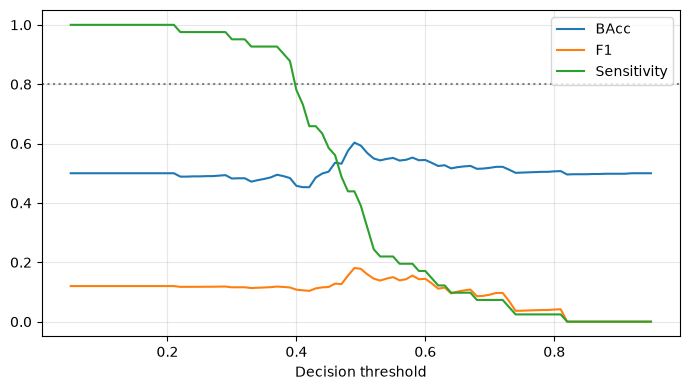

In [ ]:
def f1_curve(prob, y_true):
    return np.array([f1_score(y_true, (prob >= t).astype(int), zero_division=0) for t in thresholds])

def sens_curve(prob, y_true):
    return np.array([recall_score(y_true, (prob >= t).astype(int), zero_division=0) for t in thresholds])

oof_bacc = np.array(bacc_scores)
oof_f1 = f1_curve(oof_prob, y_train)
oof_sens = sens_curve(oof_prob, y_train)

criteria = {
    "max BAcc": thresholds[int(np.argmax(oof_bacc))],
    "max F1": thresholds[int(np.argmax(oof_f1))],
    "sensitivity ≥ 0.80": thresholds[np.where(oof_sens >= 0.80)[0].max()]
}

rows = []
for name, t in criteria.items():
    r = evaluate_model(name, y_test, stack_prob, threshold=t)
    oof_pred = (oof_prob >= t).astype(int)
    rows.append({"criterion": name, "threshold": round(float(t), 2),
                 "OOF sens": round(recall_score(y_train, oof_pred), 3),
                 "OOF spec": round(1 - oof_pred[y_train == 0].mean(), 3),
                 **{c: round(r[c], 3) for c in ["BAcc", "Sensitivity", "Specificity", "Precision", "F1"]},
                 "TP": r["TP"], "FP": r["FP"], "FN": r["FN"], "TN": r["TN"]})
print(pd.DataFrame(rows).to_string(index=False))

plt.figure(figsize=(7, 4))
plt.plot(thresholds, oof_bacc, label="BAcc")
plt.plot(thresholds, oof_f1, label="F1")
plt.plot(thresholds, oof_sens, label="Sensitivity")
plt.axhline(0.80, color="gray", linestyle=":")
plt.xlabel("Decision threshold")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Критерії max BAcc і max F1 вибирають однаковий поріг 0.49 (OOF sensitivity 0.439, specificity 0.767), і на тесті це дає sensitivity 0.714, specificity 0.751, precision 0.167, F1 0.270 (TP 10, FP 50, FN 4). Критерій sensitivity ≥ 0.80 дає поріг 0.39 (OOF sensitivity 0.878, але specificity лише 0.090) і на тесті перетворюється на тривіальну систему, яка позначає ризиковими всіх 215 пацієнток: sensitivity 1.000, specificity 0.000, 201 хибнопозитивний. Причина в тому, що OOF-ймовірності стекінгу зосереджені у вузькій смузі навколо 0.4 – 0.5, тому вимога sensitivity ≥ 0.80 вимагає опуститись нижче майже всіх значень. Тобто клінічний компроміс різкий: стабільно високу чутливість ця модель може дати лише ціною втрати практичної корисності.

# Експеримент 6. Random seeds та різні розбиття

In [ ]:
tree_rows = {"Random Forest": [], "Extra Trees": []}
for name in tree_rows:
    for s in SEEDS:
        m = build_models(s)[name].fit(X_train, y_train)
        tree_rows[name].append(evaluate_model(name, y_test, m.predict_proba(X_test)[:, 1]))

print("5 seeds моделі, один split (мінімум-максимум PR_AUC у дужках):")
print(pd.DataFrame({k: {**mean_std(v), "PR_AUC min-max": f"{min(r['PR_AUC'] for r in v):.3f}-{max(r['PR_AUC'] for r in v):.3f}"} for k, v in tree_rows.items()}).T.to_string())

5 seeds моделі, один split (мінімум-максимум PR_AUC у дужках):
                        BAcc    Sensitivity    Specificity             F1        ROC_AUC         PR_AUC PR_AUC min-max
Random Forest  0.550 ± 0.015  0.129 ± 0.029  0.971 ± 0.002  0.166 ± 0.036  0.715 ± 0.007  0.199 ± 0.003    0.195-0.202
Extra Trees    0.566 ± 0.000  0.143 ± 0.000  0.990 ± 0.000  0.222 ± 0.000  0.762 ± 0.010  0.223 ± 0.002    0.221-0.228


In [ ]:
split_results = []
t0 = time.time()
for split_seed in SEEDS:
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=split_seed)
    ms = build_models(split_seed)
    probs = {}
    for name, m in ms.items():
        probs[name] = m.fit(Xtr, ytr).predict_proba(Xte)[:, 1]
    probs["Soft Voting"] = np.mean([probs[n] for n in ms], axis=0)
    st = StackingClassifier(
        estimators=[(k, v) for k, v in zip(["lr", "rf", "extra", "boost"], ms.values())],
        final_estimator=LogisticRegression(max_iter=3000, class_weight="balanced"),
        stack_method="predict_proba", cv=5
    ).fit(Xtr, ytr)
    probs["Stacking"] = st.predict_proba(Xte)[:, 1]
    for name, p in probs.items():
        r = evaluate_model(name, yte, p)
        r["split"] = split_seed
        r["n_pos_test"] = int(yte.sum())
        split_results.append(r)
print("Час, с:", round(time.time() - t0, 1))

split_df = pd.DataFrame(split_results)
order = ["Logistic Regression", "Random Forest", "Extra Trees", "Boosting", "Soft Voting", "Stacking"]
summary = pd.DataFrame({name: mean_std(split_df[split_df["Model"] == name].to_dict("records")) for name in order}).T
print("5 різних розбиттів train/test (середнє ± std), поріг 0.5:")
print(summary.to_string())
print("Кількість позитивних у тесті по розбиттях:", split_df.drop_duplicates("split")["n_pos_test"].tolist())
print(split_df.pivot(index="Model", columns="split", values="PR_AUC").loc[order].round(3).to_string())

Час, с: 30.1
5 різних розбиттів train/test (середнє ± std), поріг 0.5:
                              BAcc    Sensitivity    Specificity             F1        ROC_AUC         PR_AUC
Logistic Regression  0.620 ± 0.042  0.414 ± 0.070  0.826 ± 0.043  0.218 ± 0.052  0.623 ± 0.049  0.177 ± 0.052
Random Forest        0.555 ± 0.025  0.143 ± 0.045  0.966 ± 0.017  0.178 ± 0.059  0.710 ± 0.039  0.176 ± 0.025
Extra Trees          0.530 ± 0.003  0.071 ± 0.000  0.988 ± 0.005  0.115 ± 0.007  0.719 ± 0.046  0.193 ± 0.036
Boosting             0.525 ± 0.026  0.057 ± 0.053  0.992 ± 0.004  0.093 ± 0.088  0.665 ± 0.035  0.185 ± 0.056
Soft Voting          0.533 ± 0.016  0.086 ± 0.029  0.980 ± 0.007  0.126 ± 0.043  0.722 ± 0.025  0.213 ± 0.025
Stacking             0.610 ± 0.049  0.443 ± 0.095  0.777 ± 0.015  0.191 ± 0.038  0.651 ± 0.063  0.158 ± 0.023
Кількість позитивних у тесті по розбиттях: [14, 14, 14, 14, 14]
split                    0      1      2      3      4
Model                                   

Спочатку змінювались лише seeds моделей при фіксованому розбитті: Random Forest і Extra Trees дають дуже стабільні результати (PR-AUC 0.195 – 0.202 і 0.221 – 0.228, std ROC-AUC 0.007 і 0.010). Але при п'яти різних розбиттях train/test (завжди 14 позитивних у тесті) розкид значно більший: наприклад PR-AUC Logistic Regression 0.177 ± 0.052 (від 0.085 до 0.245), Boosting 0.185 ± 0.056 (від 0.134 до 0.284), Soft Voting 0.213 ± 0.025, Stacking 0.158 ± 0.023. Середні значення при порозі 0.5: BAcc Logistic Regression 0.620 ± 0.042, Stacking 0.610 ± 0.049, Random Forest 0.555, Soft Voting 0.533, Extra Trees 0.530, Boosting 0.525; sensitivity 0.414, 0.443, 0.143, 0.086, 0.071 і 0.057. ROC-AUC найвищий у Soft Voting (0.722 ± 0.025) та Extra Trees (0.719), а найнижчий у Logistic Regression (0.623) і Stacking (0.651). Отже, розкид між розбиттями (0.02 – 0.06) у кілька разів більший за розкид між seeds моделі і порівнянний з різницею між моделями, тому порядок моделей на одному розбитті, зокрема на основному, ненадійний. Єдина стабільна закономірність: дерева та Voting при порозі 0.5 мають sensitivity 0.06 – 0.14, а Logistic Regression та Stacking (зі зваженими класами) 0.41 – 0.44.

# Завдання 9. Diversity та disagreement

> Проаналізувати випадки disagreement між базовими моделями та ансамблем. Проаналізувати diversity.

                     Logistic Regression  Random Forest  Extra Trees  \
Logistic Regression                1.000          0.354        0.331   
Random Forest                      0.354          1.000        0.882   
Extra Trees                        0.331          0.882        1.000   
Boosting                           0.033          0.570        0.506   
Voting                             0.636          0.908        0.876   
Stacking                           0.536          0.904        0.927   

                     Boosting  Voting  Stacking  
Logistic Regression     0.033   0.636     0.536  
Random Forest           0.570   0.908     0.904  
Extra Trees             0.506   0.876     0.927  
Boosting                1.000   0.621     0.658  
Voting                  0.621   1.000     0.982  
Stacking                0.658   0.982     1.000  


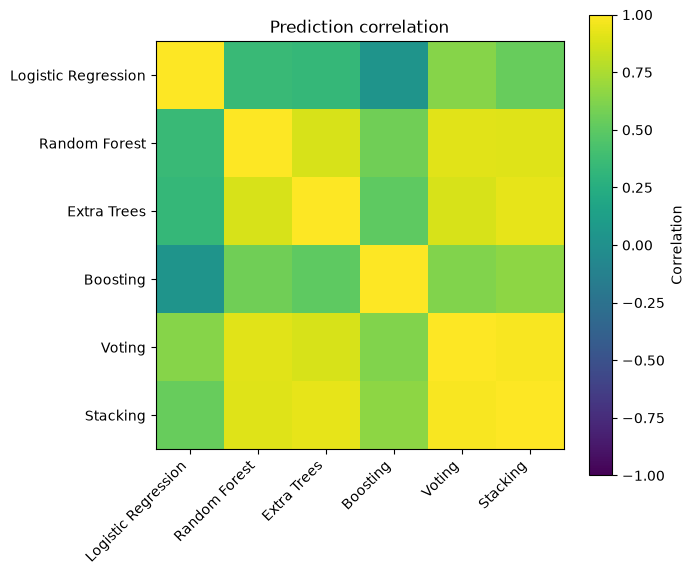

In [ ]:
prob_df = pd.DataFrame(test_probabilities)
prob_df["Voting"] = voting_prob
prob_df["Stacking"] = stack_prob

corr = prob_df.corr()
print(corr.round(3))

plt.figure(figsize=(7, 6))
plt.imshow(corr.values, vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr)), corr.columns)
plt.title("Prediction correlation")
plt.tight_layout()
plt.show()

Кореляція між прогнозованими ймовірностями дуже різна: Random Forest і Extra Trees 0.882 (схожі моделі), Logistic Regression із Boosting лише 0.033, із Random Forest 0.354, з Extra Trees 0.331, Boosting із Random Forest 0.570 і з Extra Trees 0.506. Тобто базові моделі справді різнорідні: лінійна регресія і дерева (особливо boosting) майже не збігаються. Voting і Stacking дуже схожі між собою (0.982) і з Random Forest та Extra Trees (0.90 – 0.93), бо ансамблі значною мірою повторюють дерева. Різнорідність не перетворилась на кращі результати, бо різні моделі виявляють різні позитивні випадки, але слабко.

In [ ]:
pred_table = pd.DataFrame({
    name: (prob >= 0.5).astype(int)
    for name, prob in test_probabilities.items()
})

pred_table["Voting"] = (voting_prob >= 0.5).astype(int)
pred_table["Stacking"] = (stack_prob >= best_threshold).astype(int)
pred_table["True"] = y_test.reset_index(drop=True)

pred_cols = [c for c in pred_table.columns if c != "True"]
pred_table["n_positive_votes"] = pred_table[pred_cols].sum(axis=1)

disagreement = pred_table[
    (pred_table["n_positive_votes"] > 0) &
    (pred_table["n_positive_votes"] < len(pred_cols))
]
print(disagreement.head(20))
print("Disagreement cases:", len(disagreement))
print("Серед них справжніх позитивних:", int((disagreement["True"] == 1).sum()))
print("Усі моделі позначили позитивним:", int((pred_table["n_positive_votes"] == len(pred_cols)).sum()))
print("Жодна модель не позначила позитивним:", int((pred_table["n_positive_votes"] == 0).sum()))

positives = pred_table[pred_table["True"] == 1]
print("\nСправжні позитивні (кількість моделей, що їх виявили):")
print(positives[pred_cols + ["n_positive_votes"]].to_string())
print("\nЗнайдено справжніх позитивних кожною моделлю:", positives[pred_cols].sum().to_dict())
print("Хибнопозитивних кожною моделлю:", pred_table[pred_table["True"] == 0][pred_cols].sum().to_dict())

    Logistic Regression  Random Forest  Extra Trees  Boosting  Voting  \
0                     1              0            0         0       0   
1                     0              0            0         0       0   
7                     1              0            0         0       0   
8                     1              0            0         0       0   
11                    0              0            0         0       0   
13                    1              0            0         0       0   
14                    0              0            0         1       0   
15                    1              1            0         0       0   
24                    1              0            0         0       0   
25                    0              0            0         0       0   
30                    0              0            0         0       0   
33                    1              0            0         0       0   
37                    1              0            0

Для 68 із 215 тестових пацієнток (32%) моделі не збігаються, для 147 жодна модель не позначила позитивним, і для жодної всі шість не позначили позитивним. З 14 справжніх позитивних виявлено моделями так: Stacking 10, Logistic Regression 7, Random Forest 2, Extra Trees 2, Soft Voting 2, Boosting 1; чотири випадки (рядки 74, 93, 150, 168) не знайшла жодна модель. Лише два позитивні випадки (57 і 123) знайшли чотири або п'ять моделей, а шість інших випадків (рядки 13, 24, 49, 91, 100, 147) знайшли лише Logistic Regression і Stacking, ще два (136 і 193) лише Stacking. Ціна цього: хибнопозитивних у Stacking 50, у Logistic Regression 36, а в Random Forest, Extra Trees, Boosting і Voting 6, 2, 3 і 3. Ансамблі дерев і Voting виявляють мало позитивних, бо їх ймовірності для рідкісного класу низькі, а Stacking виявляє більше за рахунок зваженої мета-моделі, тобто за рахунок зсуву порогу, а не кращої класифікації.

# Завдання 10. Вибір системи для скринінгу

> Сформулювати, яку систему ви обрали б для скринінгової задачі та чому.

Жодна з побудованих систем не є надійною для самостійного скринінгу. Найвищий ROC-AUC на п'яти розбиттях має Soft Voting (0.722) та Extra Trees (0.719), але при порозі 0.5 вони виявляють лише 7 – 9% позитивних. Системи зі зваженими класами (Logistic Regression і Stacking) виявляють близько 41 – 44% при specificity близько 0.78 – 0.83. Для скринінгу, де пропущений випадок (FN) цінніший за хибну тривогу (FP), я обрав би Stacking із порогом, підібраним на out-of-fold прогнозах навчальної частини (на основному розбитті sensitivity 0.714, specificity 0.751, 10 із 14 позитивних), але з низкою застережень. Він дає лише precision 0.167: приблизно п'ять із шести пацієнток, позначених ризиковими, мають негативну біопсію, тому система придатна лише для пріоритезації подальшого обстеження, а не для діагнозу. Різниця між Stacking і простішою Logistic Regression за BAcc на п'яти розбиттях (0.610 проти 0.620) в межах шуму, тому за рівної якості доцільніше простіша інтерпретована регресія. Усі висновки спираються на 55 позитивних випадків (14 у тесті), тому потрібна перевірка на більшій вибірці. Конкретну вартість FN і FP в роботі не задано, тому вибір порогу за критерієм sensitivity ≥ 0.80 не прийнятий: на цих даних він перетворює систему на таку, що позначає ризиковими всіх.

# Додаткове завдання підвищеної складності

> Оберіть один варіант: (1) реалізуйте weighted soft voting і оптимізуйте ваги моделей; (2) додайте probability calibration та дослідіть Brier score/calibration curve; (3) сформуйте cost-sensitive criterion, де false negative має більшу вартість за false positive; (4) порівняйте stacking із simple averaging при однаковому наборі базових моделей.

Обрано варіант (4): порівняння Stacking із простим усередненням (Soft Voting) на тому самому наборі з чотирьох базових моделей.

In [ ]:
paired = split_df.pivot(index="split", columns="Model", values="PR_AUC")
paired_b = split_df.pivot(index="split", columns="Model", values="BAcc")
paired_r = split_df.pivot(index="split", columns="Model", values="ROC_AUC")

cmp = pd.DataFrame({
    "PR_AUC: Stacking − Voting": paired["Stacking"] - paired["Soft Voting"],
    "ROC_AUC: Stacking − Voting": paired_r["Stacking"] - paired_r["Soft Voting"],
    "BAcc: Stacking − Voting": paired_b["Stacking"] - paired_b["Soft Voting"]
})
print(cmp.round(3).to_string())
print("Середня різниця:")
print(cmp.mean().round(3).to_string())
print("Розбиттів, де Stacking кращий за PR_AUC:", int((cmp.iloc[:, 0] > 0).sum()), "з", len(cmp))

rows = {}
for name in ["Soft Voting", "Stacking"]:
    sub = split_df[split_df["Model"] == name]
    rows[name] = {"Sensitivity": f"{sub['Sensitivity'].mean():.3f}", "Specificity": f"{sub['Specificity'].mean():.3f}",
                  "FP (сер.)": f"{sub['FP'].mean():.1f}", "FN (сер.)": f"{sub['FN'].mean():.1f}"}
print(pd.DataFrame(rows).T.to_string())
print("Основний split: PR_AUC Voting", round(average_precision_score(y_test, voting_prob), 3), ", Stacking", round(average_precision_score(y_test, stack_prob), 3))

       PR_AUC: Stacking − Voting  ROC_AUC: Stacking − Voting  BAcc: Stacking − Voting
split                                                                                
0                         -0.044                      -0.066                    0.107
1                         -0.046                      -0.096                    0.072
2                         -0.041                      -0.147                    0.000
3                         -0.053                      -0.042                    0.096
4                         -0.092                      -0.007                    0.110
Середня різниця:
PR_AUC: Stacking − Voting    -0.055
ROC_AUC: Stacking − Voting   -0.072
BAcc: Stacking − Voting       0.077
Розбиттів, де Stacking кращий за PR_AUC: 0 з 5
            Sensitivity Specificity FP (сер.) FN (сер.)
Soft Voting       0.086       0.980       4.0      12.8
Stacking          0.443       0.777      44.8       7.8
Основний split: PR_AUC Voting 0.23 , Stacking 0.229


На п'яти різних розбиттях Stacking не кращий за просте усереднення (Soft Voting) за метриками, що не залежать від порогу: різниця PR-AUC (Stacking мінус Voting) від −0.092 до −0.041, у середньому −0.055, і Stacking не кращий у жодному з 5 розбиттів; різниця ROC-AUC в середньому −0.072. Натомість за BAcc при порозі 0.5 Stacking кращий у середньому на 0.077 (в одному розбитті різниці немає), бо sensitivity 0.443 проти 0.086 при 44.8 проти 4.0 хибнопозитивних у середньому. Тобто виграш у BAcc виникає через зсув порогу у зваженої мета-моделі, а не через краще впорядкування пацієнток; на основному розбитті PR-AUC обох майже однаковий (0.229 і 0.230). Тому для однакового набору базових моделей stacking на цих даних не дає переваги над простим усередненням, хоча ускладнює систему.

# Висновки

У цьому практикумі ми навчились будувати preprocessing без leakage, порівнювати різнорідні базові моделі, Bagging і Boosting, формувати Soft Voting та Stacking ансамблі, застосовувати class weights і підбір порогу за out-of-fold прогнозами та оцінювати моделі за BAcc, sensitivity, specificity, F1, ROC-AUC і PR-AUC на незбалансованих клінічних даних. Метою роботи було дослідити ансамблеві методи обчислювального інтелекту на біомедичній задачі з незбалансованими класами та пропущеними значеннями, порівняти Bagging і Boosting, сформувати Voting і Stacking, дослідити вплив class weighting і threshold tuning та оцінити здатність виявляти рідкісний клінічно важливий клас, і її досягнуто.

**Результати.** Клас рідкісний (55 із 858, 6.4%), а в тесті лише 14 позитивних. Моделі дерев і Soft Voting при порозі 0.5 виявляють 1 – 2 із 14 позитивних (accuracy 0.92 – 0.93 близька до константного 0.935), а Logistic Regression і Stacking зі зваженими класами виявляють 7 і 9 (з 36 і 45 хибнопозитивними). Підбір порогу за OOF (0.49) дав Stacking 10 із 14 при specificity 0.751. Class weighting змінює робочу точку (sensitivity Logistic Regression 0.071 → 0.500), але не покращує PR-AUC і ROC-AUC. Склад Voting не гарантує виграшу при більшій кількості моделей, а Random Forest як мета-модель стекінгу значно гірша за Logistic Regression. Stacking не кращий за просте усереднення за PR-AUC (в 0 із 5 розбиттів), а його перевага в BAcc пояснюється зсувом порогу.

**Обмеження.** Усі різниці малі порівняно з розкидом між розбиттями (PR-AUC 0.02 – 0.06), тому порядок моделей на одному розбитті ненадійний. Максимальний ROC-AUC близько 0.72 – 0.78, precision найкращих налаштувань близько 0.17, тож жодна система не придатна для самостійного скринінгу, а лише для пріоритезації обстеження; вартості FN і FP в роботі не задано.

# Контрольні питання

**1. Чому ансамбль може працювати краще за окрему модель?**

Одна модель має власні систематичні помилки, а ансамбль поєднує кілька моделей так, щоб їхні помилки частково компенсували одна одну. Ключова умова полягає в тому, що базові моделі повинні бути не лише достатньо сильними, але й відрізнятися за поведінкою.

**2. Чим Bagging відрізняється від Boosting?**

Bagging навчає багато моделей незалежно на різних bootstrap-вибірках і агрегує їхні прогнози; Random Forest додатково випадково обмежує набір ознак у деревах, зменшуючи кореляцію між ними. Boosting будує моделі послідовно, і кожна наступна концентрується на помилках попередніх. У практикумі як boosting використовується HistGradientBoosting.

**3. Чим Soft Voting відрізняється від Hard Voting?**

Soft Voting усереднює ймовірності, які повертають моделі, і приймає рішення за усередненою ймовірністю. Hard Voting натомість голосує за класи: кожна модель віддає свій передбачений клас, і обирається клас, який набрав більше голосів. Soft Voting використовує більше інформації, бо враховує впевненість моделей.

**4. Як працює Stacking?**

Stacking використовує прогнози базових моделей як нові ознаки для meta-model, яка вчиться оптимально їх поєднувати. Для корекції meta-model навчається на out-of-fold прогнозах базових моделей, тобто на прогнозах для об'єктів, яких ці моделі не бачили під час навчання. У `StackingClassifier` це забезпечується параметром `cv`.

**5. Чому meta-model у stacking не можна навчати на звичайних in-sample прогнозах?**

Базові моделі, особливо дерева, на навчальних даних видають надто впевнені, майже ідеальні прогнози, бо вони бачили ці об'єкти. Meta-model, навчена на таких прогнозах, переоцінила б надійність базових моделей і не змогла б узагальнитись на нові дані. Тому використовуються out-of-fold прогнози.

**6. Чому accuracy є небезпечною метрикою для сильно незбалансованих даних?**

Якщо позитивний клас рідкісний, accuracy може бути високою навіть для практично непридатної моделі, наприклад такої, що завжди передбачає негативний клас. Тому основний аналіз виконується за sensitivity, specificity, balanced accuracy, F1, ROC-AUC і особливо PR-AUC.

**7. Чим ROC-AUC відрізняється від PR-AUC?**

ROC-AUC вимірює здатність упорядковувати об'єкти за ймовірністю на кривій залежності sensitivity від частки хибнопозитивних, а PR-AUC вимірює площу під кривою precision–recall. Для рідкісного позитивного класу ROC-AUC може залишатися високою через велику кількість негативних об'єктів, а Precision–Recall curve часто є інформативнішою, бо безпосередньо враховує precision позитивного класу.

**8. Що означають sensitivity та specificity?**

Sensitivity (recall) це частка справжніх позитивних випадків, які модель виявила: TP / (TP + FN). Specificity це частка справжніх негативних випадків, які модель правильно визнала негативними: TN / (TN + FP). У клінічній задачі sensitivity показує здатність знайти рідкісний важливий клас, а specificity показує, наскільки модель уникає хибних тривог.

**9. Навіщо змінювати decision threshold і чому його не можна підбирати на test set?**

Поріг 0.5 не є обов'язково оптимальним для незбалансованої медичної задачі, а зміна порогу дозволяє керувати компромісом між sensitivity і specificity відповідно до клінічної ціни помилок. Якщо підбирати поріг на test set, тест перестає бути незалежним і оцінка якості стає завищеною, тому поріг підбирається лише за out-of-fold прогнозами на training set.

**10. Чому diversity базових моделей важлива для ансамблю?**

Ансамбль корисний тоді, коли моделі роблять не повністю однакові помилки. Якщо їхні прогнози майже збігаються (кореляція ймовірностей близька до 1), усереднення нічого не додає, тому для виграшу від ансамблю базові моделі повинні відрізнятися за поведінкою.